# Garbage Classification

## 4. Trích đặc trưng học sâu

**Mục tiêu.** Biến mỗi ảnh thành **một vector số có độ dài cố định** cho các mô hình cổ điển ở notebook 05 (Logistic Regression, SVM, Random Forest). Đặc trưng được lấy từ **mạng nơ-ron đã huấn luyện sẵn trên ImageNet** (1,28 triệu ảnh, 1000 lớp). Mạng được **giữ nguyên trọng số** (không huấn luyện thêm); ta chỉ bỏ lớp phân loại cuối và lấy vector ở lớp ngay trước nó.

| # | Đặc trưng | Kiến trúc | Trọng số (torchvision) | Lấy ở đâu | Số chiều |
|---|---|---|---|---|---|
| 1 | `resnet50` | ResNet-50 (CNN, 2015) | `IMAGENET1K_V1` | global average pooling | 2048 |
| 2 | `efficientnet_b0` | EfficientNet-B0 (CNN, 2019) | `IMAGENET1K_V1` | global average pooling | 1280 |
| 3 | `vit_b16` | ViT-B/16 (Transformer, 2021) | `IMAGENET1K_V1` | token `[CLS]` sau LayerNorm cuối | 768 |

**Chọn trọng số.** Mỗi mô hình dùng bộ trọng số ImageNet-1k của torchvision (top-1 ImageNet lần lượt 76.1%, 77.7%, 81.1%). Ba bộ này được train bằng **công thức khác nhau**: ResNet-50 V1 theo công thức cơ bản, còn ViT-B/16 cần augmentation và regularization mạnh (tương tự DeiT) mới train tốt được chỉ với ImageNet-1k. Vì vậy so sánh giữa ba mạng là so sánh *kiến trúc + công thức train + dữ liệu pretrain*, không riêng kiến trúc.

**Cách làm này có đúng về mặt học thuật không?** Có. Đây là cách *transfer learning* dạng **fixed feature extractor** (còn gọi *linear probe*), một giao thức chuẩn:
- DeCAF (Donahue et al., 2014) và "CNN Features off-the-shelf" (Razavian et al., 2014) cho thấy vector lớp áp chót của CNN train trên ImageNet là đặc trưng tổng quát, dùng với SVM/LR cho kết quả tốt trên nhiều bài toán khác ImageNet.
- Kornblith et al. (2019), "Do Better ImageNet Models Transfer Better?", dùng đúng giao thức này (đóng băng mạng, lấy vector lớp áp chót, huấn luyện bộ phân loại tuyến tính) để so sánh 16 mạng trên 12 tập dữ liệu. Dosovitskiy et al. (2021) cũng dùng linear probe để đánh giá biểu diễn của ViT.

Fine-tune toàn bộ mạng để dành cho notebook 06. Đặc trưng đóng băng **thường** cho kết quả thấp hơn fine-tune, nhất là khi dữ liệu khác xa ImageNet, nhưng không phải luôn luôn: fine-tune trên dữ liệu ít vẫn có thể overfit.

**Luồng xử lý chung** (code trong phần *Deep* của [`modules/extract.py`](../modules/extract.py)):

```
ảnh gốc ──(load_image: RGB, cạnh ngắn → 256 rồi cắt giữa 224×224)──> artifacts/cache/images_224_*.npy  (uint8, làm 1 lần ~35 giây)
      ──> từng batch 64 ảnh: chuẩn hóa mean/std ImageNet (= eval_tf của 02) ──> mạng pretrain, đã bỏ head, chế độ eval
      chạy trên GPU (mps/cuda) cho 15 866 ảnh, giữ thứ tự dòng của meta.csv ──> ma trận (15866, số chiều)
      ──> artifacts/features/<tên>.npy  (float32, dòng i = ảnh có idx = i)
      ──> artifacts/features/<tên>.json (trọng số, cỡ ảnh, cách chuẩn hóa, thiết bị đã dùng)
```

**Vì sao cache ảnh?** Giải mã JPEG + resize là việc của CPU. Ban đầu việc này do DataLoader 8 worker làm song song với GPU, nhưng mỗi worker nạp lại cả PyTorch nên máy RAM 8 GB bị swap: ViT chỉ đạt ~8 ảnh/s (29 phút cho cả tập). Bây giờ ảnh được chuẩn bị sẵn **một lần** (~35 giây, song song nhiều tiến trình) thành mảng uint8 ~2.4 GB trong `artifacts/cache/` (không commit), cả ba mạng đọc thẳng từ đó: ViT còn ~17 phút, đặc trưng không đổi. Cache tự sinh lại nếu `meta.csv`, cỡ ảnh hoặc `[RESIZE]` thay đổi; xóa thư mục `artifacts/cache/` khi không cần nữa.

**Đổi phương án để so sánh (ablation)** bằng các khối `# ===== [TÊN] CÁCH n ... =====` trong `modules/extract.py` (comment khối đang dùng, bỏ comment khối khác rồi chạy lại):

| Điểm lựa chọn | Đang dùng | Phương án khác |
|---|---|---|
| `[RESNET_WEIGHTS]` | `IMAGENET1K_V1` (công thức train gốc, top-1 76.1%) | `IMAGENET1K_V2` (công thức mới, nhiều augmentation/regularization, top-1 80.9%) |
| `[DEEP_SIZE]` | ảnh 224 (đúng độ phân giải lúc pretrain) | ảnh 128 (ViT-B/16 không hỗ trợ nên bị bỏ qua) |
| `[DEEP_NORM]` | lưu vector thô | L2-chuẩn hóa từng dòng |

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # để import được modules/ khi chạy từ thư mục notebooks/

import json
import modules.extract as ex

cfg = ex.load_config()   # config.yaml + data/processed/config.json (seed, img_size, mean/std) của 02
print("thiết bị:", ex.get_device())

thiết bị: mps


### 4.1. Nạp kết quả của bước prep (02)
`meta.csv` liệt kê 15 866 ảnh, `ex.load_meta()` thêm cột `idx` = số thứ tự dòng, và **dòng i của mọi file đặc trưng ứng với dòng i của `meta.csv`**. `config.json` của 02 cho biết `img_size` = 224 và mean/std ImageNet dùng để chuẩn hóa ảnh.

Notebook này **không dùng `splits`**: không có bước nào học từ dữ liệu, nên mọi ảnh được xử lý như nhau.

In [2]:
meta, splits = ex.load_meta()
print(len(meta), "ảnh;", " | ".join(f"{k} {len(v)}" for k, v in splits.items()))
print(cfg["prep"])

15866 ảnh; train 10153 | val 2539 | test 3174
{'seed': 42, 'img_size': 224, 'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225], 'test_size': 0.2, 'val_size': 0.2}


### 4.2. Đóng băng mạng và vì sao không rò rỉ dữ liệu

Ba điều kiện để đặc trưng hợp lệ, đã cài sẵn trong `ex.extract_deep`:
1. **Đóng băng hoàn toàn**: `model.eval()` (BatchNorm dùng thống kê đã học trên ImageNet, Dropout tắt) và `torch.inference_mode()` (không tính gradient, không cập nhật trọng số). Mỗi ảnh được biến đổi **độc lập** bằng một hàm cố định học từ ImageNet, nên trích trên cả train, val lẫn final test **không làm rò rỉ thông tin** giữa các tập.
2. **Không augmentation**: cùng một ảnh luôn cho cùng một vector (đã kiểm tra: chạy hai lần cho kết quả trùng khớp; chạy trên GPU Mac (MPS) so với CPU lệch dưới 1e-4).
3. **Tiền xử lý khớp lúc pretrain**: RGB, 224×224, chuẩn hóa mean/std ImageNet. Ảnh được nạp bằng `load_image`, trùng từng pixel với `eval_tf` của 02 (cạnh ngắn → 256, cắt giữa 224).

Mọi bước có học từ dữ liệu sau này (StandardScaler, PCA...) vẫn phải **fit trên train** ở notebook 05.

**Hạn chế cần biết:**
- *Lệch miền (domain shift)*: ảnh rác khác ảnh ImageNet, dù ImageNet có sẵn nhiều lớp gần gũi (chai, giày, pin, hộp carton...).
- Dataset được thu thập từ web, nên không loại trừ được việc một số ảnh từng xuất hiện trong ImageNet (rủi ro nhỏ).
- *ViT chỉ pretrain trên ImageNet-1k*: kết quả mạnh của ViT trong bài gốc đến từ pretrain trên ImageNet-21k hoặc JFT-300M; khi chỉ có ImageNet-1k, ViT không có lợi thế rõ so với CNN. Nếu `vit_b16` không vượt `resnet50` ở notebook 05, không nên kết luận chung rằng "Transformer kém hơn CNN".
- *Chỉ lấy lớp áp chót*: lớp này chuyên biệt cho 1000 lớp ImageNet; khi miền dữ liệu khác xa, đặc trưng ở các lớp giữa đôi khi chuyển giao tốt hơn. Notebook này không khảo sát điều đó.
- torchvision gợi ý tiền xử lý hơi khác nhau cho từng bộ trọng số (vd EfficientNet resize bicubic). Ở đây dùng chung một pipeline cho cả ba để nhất quán với 02 và 06; chênh lệch không đáng kể.

**Ảnh minh họa**: một ảnh giày lấy ngẫu nhiên (cố định theo `seed`). Mỗi phần bên dưới vẽ: ảnh đầu vào, vector đặc trưng, và top-5 lớp ImageNet khi tạm gắn lại head gốc. Phần top-5 vừa cho thấy mạng "nhận ra" gì, vừa kiểm tra trọng số và chuẩn hóa đã đúng; nó **không** được dùng làm đặc trưng.

In [3]:
shape_idx, shape_path, _ = ex.pick_examples(meta, ["shoes"], seed=cfg["seed"])[0]
shape_idx, shape_path

(14268, '../data/raw/garbage_classification_enhanced/shoes/shoes901.jpg')

### 4.3. ResNet-50 (`resnet50`)

**Ý tưởng.** Một CNN gồm 50 lớp, xếp thành 4 tầng; mỗi tầng giảm kích thước không gian và tăng số kênh, đi từ cạnh/màu (tầng đầu) đến bộ phận và vật thể (tầng cuối). Điểm mới là **kết nối tắt (residual)**: mỗi khối học phần *chênh lệch* $F(x)$ rồi cộng vào đầu vào, $y = x + F(x)$, nhờ đó mạng rất sâu vẫn huấn luyện được.

**Lấy đặc trưng ở đâu.** Ảnh 224×224 đi qua 4 tầng thành bản đồ đặc trưng 7×7×2048. **Global average pooling** lấy trung bình 7×7 vị trí → vector **2048 chiều**; sau đó vốn là lớp `fc` 2048 → 1000 lớp ImageNet, ở đây được thay bằng `Identity`. Bản đồ đặc trưng đã qua ReLU nên mọi giá trị ≥ 0; nhưng vì là trung bình của 49 vị trí nên hiếm khi bằng đúng 0 (đo được ~0.7% giá trị bằng 0), tức vector **không thưa**.

**Vì sao `IMAGENET1K_V1`?** Đây là bộ trọng số gốc, train theo công thức cơ bản của bài ResNet. Bộ `V2` đạt top-1 ImageNet cao hơn (80.9% so với 76.1%) nhờ công thức mới với nhiều augmentation và regularization (label smoothing, mixup, cutmix...). Kornblith et al. (2019) cho thấy một số kỹ thuật regularization (label smoothing, dropout, auxiliary head) làm vector lớp áp chót **kém chuyển giao hơn** khi dùng làm đặc trưng cố định, dù độ chính xác ImageNet tăng. Bài đó không khảo sát mixup/cutmix, nên chỉ có thể nói V2 *có thể* chuyển giao kém hơn. Đây là câu hỏi mở, kiểm chứng bằng `[RESNET_WEIGHTS]` cách 2.

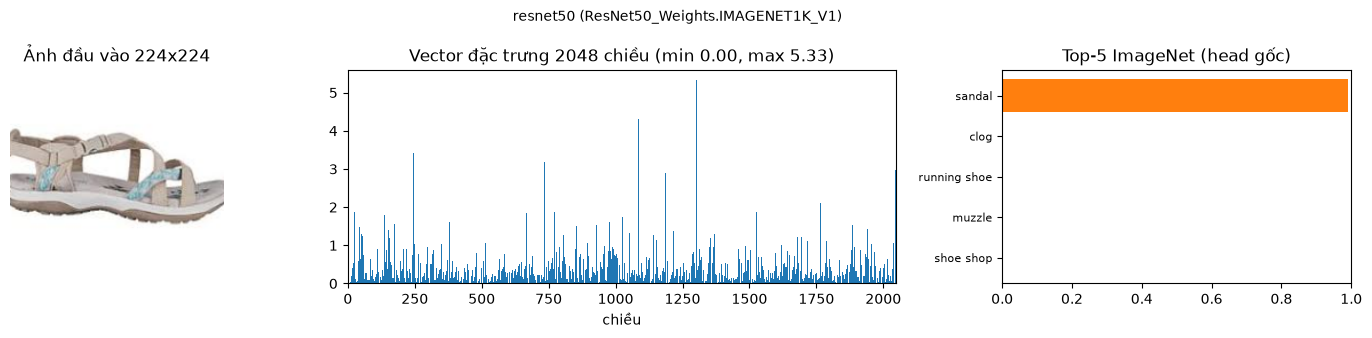

In [4]:
ex.show_deep_demo(cfg, shape_path, "resnet50");

**Trích ResNet-50 cho toàn bộ ảnh.**

In [5]:
X = ex.run_deep("resnet50", meta, cfg)

resnet50:   0%|          | 0/15866 [00:00<?, ?ảnh/s]

/Users/minhman/Downloads/Workspace/P4AI-DS/garbage-classification/modules/extract.py:692: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:214.)
  x = torch.from_numpy(np.ascontiguousarray(imgs[s:s + batch_size])).to(device)


resnet50 {'dims': 2048, 'zero_rows': 0, 'min': 0.0, 'max': 11.854089736938477, 'MB': 130.0} {'seconds': 301.9, 'device': 'mps', 'weights': 'ResNet50_Weights.IMAGENET1K_V1', 'input_size': 224, 'dims': 2048, 'preprocess': 'load_rgb -> cạnh ngắn 256 (bilinear) -> cắt giữa 224 -> chuẩn hóa mean/std ImageNet (eval_tf của 02)'}


### 4.4. EfficientNet-B0 (`efficientnet_b0`)

**Ý tưởng.** Thay vì chỉ làm mạng sâu hơn, EfficientNet **co giãn đồng thời** độ sâu, độ rộng (số kênh) và độ phân giải ảnh theo một tỷ lệ cố định (*compound scaling*); B0 là bản gốc nhỏ nhất (5,3 triệu tham số, so với 25,6 triệu của ResNet-50) nhưng đạt độ chính xác ImageNet tương đương (77.7%). Khối cơ bản là **MBConv**: tích chập depthwise (rẻ) kèm cơ chế *squeeze-and-excitation* để mạng tự chọn kênh nào quan trọng.

**Lấy đặc trưng ở đâu.** Bản đồ đặc trưng cuối 7×7×1280 → global average pooling → **1280 chiều** (bỏ khối `classifier` gồm Dropout + Linear). Hàm kích hoạt là SiLU nên có thể có giá trị âm nhỏ.

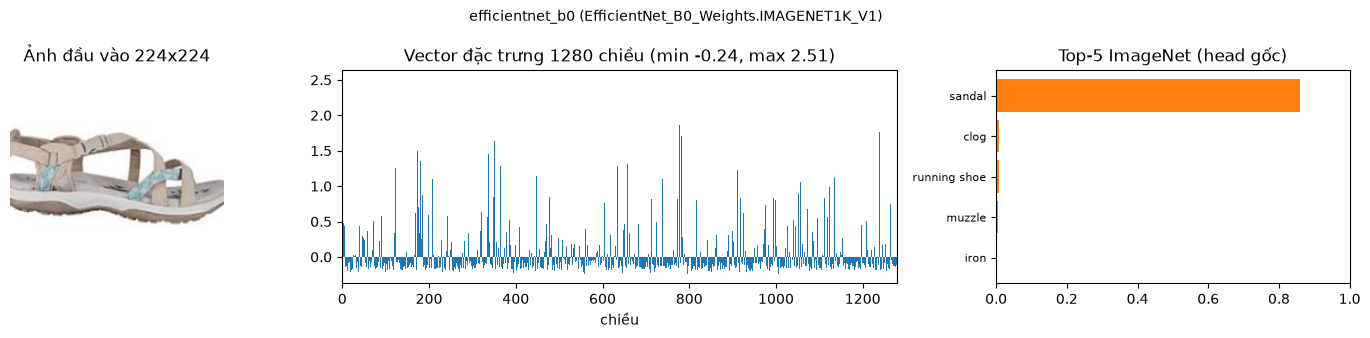

In [6]:
ex.show_deep_demo(cfg, shape_path, "efficientnet_b0");

**Trích EfficientNet-B0 cho toàn bộ ảnh.**

In [7]:
X = ex.run_deep("efficientnet_b0", meta, cfg)

efficientnet_b0:   0%|          | 0/15866 [00:00<?, ?ảnh/s]

efficientnet_b0 {'dims': 1280, 'zero_rows': 0, 'min': -0.2719722092151642, 'max': 7.684566974639893, 'MB': 81.2} {'seconds': 378.3, 'device': 'mps', 'weights': 'EfficientNet_B0_Weights.IMAGENET1K_V1', 'input_size': 224, 'dims': 1280, 'preprocess': 'load_rgb -> cạnh ngắn 256 (bilinear) -> cắt giữa 224 -> chuẩn hóa mean/std ImageNet (eval_tf của 02)'}


### 4.5. ViT-B/16 (`vit_b16`)

**Ý tưởng.** Không dùng tích chập. Ảnh 224×224 được cắt thành **196 mảnh 16×16** (lưới 14×14); mỗi mảnh được chiếu thành một vector 768 chiều (*token*), cộng thêm thông tin vị trí. Thêm một token đặc biệt **`[CLS]`** ở đầu, rồi cho 197 token qua **12 lớp Transformer**: ở mỗi lớp, *self-attention* cho mỗi token "nhìn" mọi token khác. Nhờ vậy ngay từ lớp đầu, mạng đã thấy quan hệ giữa các vùng xa nhau, khác CNN vốn chỉ nhìn cục bộ rồi mới mở rộng dần.

**Lấy đặc trưng ở đâu.** Token `[CLS]` sau LayerNorm cuối, **768 chiều**, là bản tóm tắt cả ảnh (khi pretrain, chỉ token này được đưa vào lớp phân loại). Head `heads` được thay bằng `Identity`.

**Trọng số.** `IMAGENET1K_V1` của torchvision được train từ đầu chỉ trên ImageNet-1k, với công thức tương tự DeiT (300 epoch, augmentation mạnh, mixup, cutmix, label smoothing), top-1 81.1%. Bài ViT gốc cho thấy ViT cần dữ liệu pretrain rất lớn (ImageNet-21k, JFT-300M) mới vượt CNN; bản ở đây không có lợi thế đó (xem hạn chế ở 4.2).

**Lưu ý.** Bản ViT-B/16 của torchvision gắn cố định thông tin vị trí cho lưới 14×14, nên **chỉ nhận ảnh 224×224**; khi bật `[DEEP_SIZE]` cách 2 (ảnh 128), `run_deep` sẽ bỏ qua mô hình này và in thông báo.

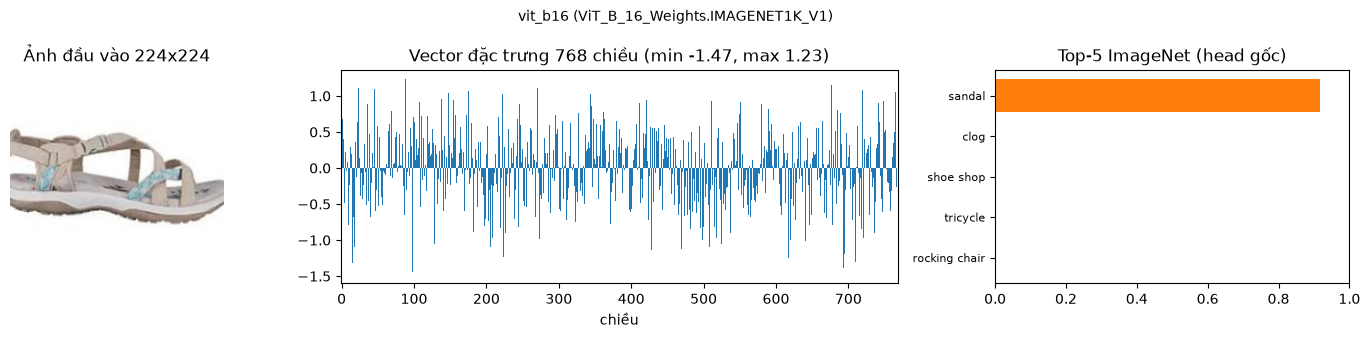

In [8]:
ex.show_deep_demo(cfg, shape_path, "vit_b16");

**Trích ViT-B/16 cho toàn bộ ảnh.**

In [9]:
X = ex.run_deep("vit_b16", meta, cfg)

vit_b16:   0%|          | 0/15866 [00:00<?, ?ảnh/s]

vit_b16 {'dims': 768, 'zero_rows': 0, 'min': -4.83143949508667, 'max': 4.6489763259887695, 'MB': 48.7} {'seconds': 1032.2, 'device': 'mps', 'weights': 'ViT_B_16_Weights.IMAGENET1K_V1', 'input_size': 224, 'dims': 768, 'preprocess': 'load_rgb -> cạnh ngắn 256 (bilinear) -> cắt giữa 224 -> chuẩn hóa mean/std ImageNet (eval_tf của 02)'}


### 4.6. Tổng hợp
Ba đặc trưng deep đã lưu và cấu hình đã dùng. Cột `giây` là thời gian trích trên toàn bộ 15 866 ảnh.

In [10]:
display(ex.feature_summary(cfg, names=list(ex.DEEP_MODELS)))
for fn in ex.DEEP_MODELS:
    path = os.path.join(cfg["features_dir"], fn + ".json")
    if os.path.exists(path):
        info = json.load(open(path))
        print(fn, {k: info.get(k) for k in ["weights", "input_size", "device", "seconds"]},
              "deep_norm:", info["extract"]["deep_norm"])

,số dòng,số chiều,MB,dòng toàn 0,giây,resize
đặc trưng,,,,,,
efficientnet_b0,15866,1280,81.2,0,378.3,short256_center_crop
resnet50,15866,2048,130.0,0,301.9,short256_center_crop
vit_b16,15866,768,48.7,0,1032.2,short256_center_crop


resnet50 {'weights': 'ResNet50_Weights.IMAGENET1K_V1', 'input_size': 224, 'device': 'mps', 'seconds': 301.9} deep_norm: raw
efficientnet_b0 {'weights': 'EfficientNet_B0_Weights.IMAGENET1K_V1', 'input_size': 224, 'device': 'mps', 'seconds': 378.3} deep_norm: raw
vit_b16 {'weights': 'ViT_B_16_Weights.IMAGENET1K_V1', 'input_size': 224, 'device': 'mps', 'seconds': 1032.2} deep_norm: raw


### 4.7. Tóm tắt và lưu ý cho bước phân loại (notebook 05)

| Đặc trưng | Kiểu | Chiều | Thang giá trị | Lưu ý khi dùng |
|---|---|---|---|---|
| `resnet50` | CNN, avg pool | 2048 | ≥ 0 (ReLU rồi lấy trung bình), không thưa | nhiều chiều nhất; LR/SVM tuyến tính nên chạy tốt |
| `efficientnet_b0` | CNN, avg pool | 1280 | gần ≥ 0 (SiLU) | mạng nhỏ nhất, nhanh nhất |
| `vit_b16` | Transformer, `[CLS]` | 768 | có âm và dương | ít chiều nhất |

- Mọi file `.npy` có **15 866 dòng theo đúng thứ tự `meta.csv`**; lấy từng tập bằng `X[splits["train"]]`, `X[splits["val"]]`, `X[splits["test"]]`.
- Đặc trưng được lưu **thô**: nên dùng `StandardScaler` (fit trên train) trước LR/SVM. Muốn thử chuẩn hóa L2 có thể bật `[DEEP_NORM]` cách 2 rồi trích lại, hoặc nhanh hơn là thêm `sklearn.preprocessing.Normalizer` vào pipeline ở 05 (không cần trích lại, vì L2 tính riêng từng dòng).
- **Ablation**: đổi khối trong `modules/extract.py` rồi chạy lại phần tương ứng; file `.json` ghi lại trọng số, cỡ ảnh, cách chuẩn hóa để đối chiếu. `[DEEP_SIZE]` = 128 cho biết đặc trưng nhạy với độ phân giải đến đâu (mạng được pretrain ở 224 nên kỳ vọng kém đi, xem FixRes, Touvron et al. 2019); `[RESNET_WEIGHTS]` = V2 kiểm tra xem công thức train nhiều regularization có làm đặc trưng chuyển giao kém hơn hay không (gợi ý từ Kornblith et al. 2019).
- **So sánh công bằng**: số chiều giữa ba đặc trưng khác nhau (768 – 2048), nên chỉnh siêu tham số (vd hệ số C của LR/SVM) **riêng cho từng đặc trưng** trên tập val, không dùng chung một bộ.
- Fine-tune ở notebook 06 thường tốt hơn đặc trưng đóng băng, và khoảng cách giữa ViT với CNN có thể khác khi fine-tune.